In [2]:
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import cv2
import matplotlib.pyplot as plt


In [3]:
# Load the pre-trained MobileNetV2 SSD model from TensorFlow Hub
model = hub.load("https://www.kaggle.com/models/tensorflow/ssd-mobilenet-v2/TensorFlow2/ssd-mobilenet-v2/1")

# Function to run object detection
def detect_objects(image):
    input_tensor = tf.convert_to_tensor(image)
    input_tensor = input_tensor[tf.newaxis, ...]
    detections = model(input_tensor)
    return detections


In [4]:
# Function to draw bounding boxes on the image
def draw_boxes(image, detections, class_names, threshold=0.5):
    height, width, _ = image.shape
    boxes = detections['detection_boxes'][0].numpy()
    scores = detections['detection_scores'][0].numpy()
    classes = detections['detection_classes'][0].numpy().astype(np.int32)
    
    for i in range(len(scores)):
        if scores[i] >= threshold:
            ymin, xmin, ymax, xmax = boxes[i]
            (left, right, top, bottom) = (xmin * width, xmax * width, ymin * height, ymax * height)
            cv2.rectangle(image, (int(left), int(top)), (int(right), int(bottom)), (0, 0, 255), 2) 
            class_name = class_names[classes[i]-1] 
            label = f"{class_name}, Score: {scores[i]:.2f}"
            cv2.putText(image, label, (int(left), int(top)-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
    return image


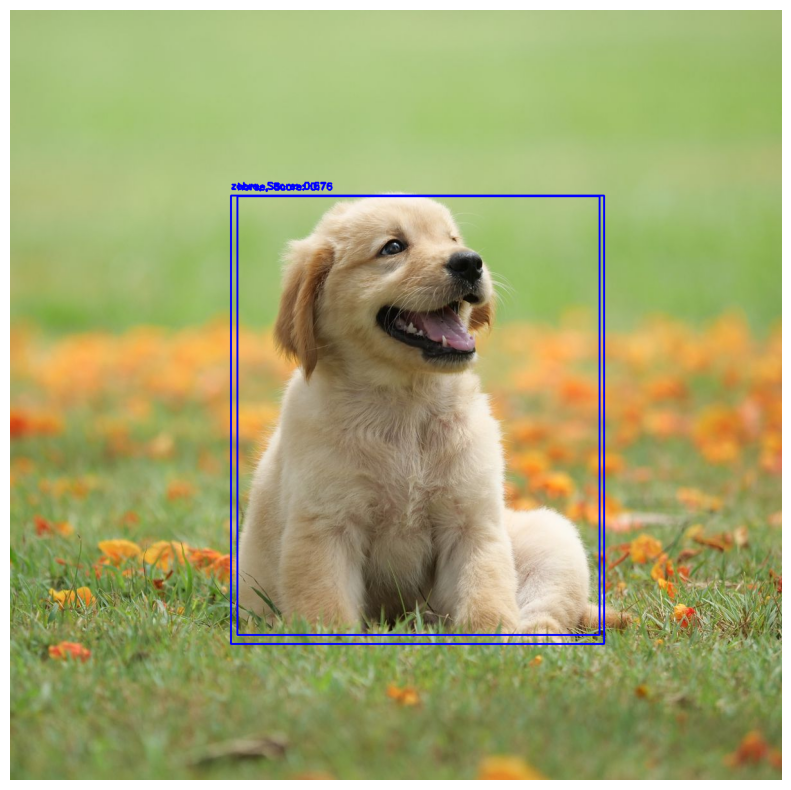

In [6]:
# Load class names
class_names_path = 'coco.names'
with open(class_names_path, 'r') as f:
    class_names = f.read().strip().split('\n')

# Test the model on a sample image
image_path = 'dog.jpg'
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
detections = detect_objects(image_rgb)
image_with_boxes = draw_boxes(image_rgb, detections, class_names)

plt.figure(figsize=(10, 10))
plt.imshow(image_with_boxes)
plt.axis('off')
plt.show()
